Untuk jaraknya sebagai berikut:

- Adelaide, Australia = -35.04172004613722, 138.81410929157082
- Baghdad, Irak = 33.324774314091385, 44.367557882870734
- Bandar Seri Begawan, Brunei = 4.891769334178615, 114.94323432386415
- Bangkok, Thailand = 13.757730777943769, 100.51216790077196
- Budapest, Hungaria = 47.491877429311565, 19.0203747674599
- Ho Chi Minh City, Vietnam = 10.794569232362448, 106.61519308039173
- Las Vegas, Amerika Serikat 36.168906289290874, -115.10366663710153
- Madrid, Spanyol = 40.41745231523501, -3.7008410257960485
- Manila, Filipina = 14.600315438573563, 120.98058833763763
- Nairobi, Kenya = -1.289474116188248, 36.82059410787391
- Osaka, Jepang = 34.69611949965089, 135.50524364079774
- Putra Jaya, Malaysia = 2.9260157158071274, 101.69231920358003
- Salatiga, Indonesia = -7.32999742665644, 110.50669704442139

Saya jadikan file: 672023081-cities.csv yang berisi:

name,description,latitude,longitude
Salatiga,Indonesia,-7.32999742665644,110.50669704442139
Adelaide,Australia,-35.04172004613722,138.81410929157082
Baghdad,Irak,33.324774314091385,44.367557882870734
Bandar Seri Begawan,Brunei,4.891769334178615,114.94323432386415
Bangkok,Thailand,13.757730777943769,100.51216790077196
Budapest,Hungaria,47.491877429311565,19.0203747674599
Ho Chi Minh City,Vietnam,10.794569232362448,106.61519308039173
Las Vegas,USA,36.168906289290874,-115.10366663710153
Madrid,Spanyol,40.41745231523501,-3.7008410257960485
Manila,Filipina,14.600315438573563,120.98058833763763
Nairobi,Kenya,-1.289474116188248,36.82059410787391
Osaka,Jepang,34.69611949965089,135.50524364079774
Putra Jaya,Malaysia,2.9260157158071274,101.69231920358003

In [3]:
import numpy as np

path_distance = lambda r,c: np.sum([np.linalg.norm(c[r[p]]-c[r[p-1]]) for p in range(len(r))])

two_opt_swap = lambda r,i,k: np.concatenate((r[0:i],r[k:-len(r)+i-1:-1],r[k+1:len(r)]))

def two_opt(cities,improvement_threshold):
    route = np.arange(cities.shape[0])
    improvement_factor = 1
    best_distance = path_distance(route,cities)

    while improvement_factor > improvement_threshold:
        distance_to_beat = best_distance

        for swap_first in range(1,len(route)-2):
            for swap_last in range(swap_first+1,len(route)):
                new_route = two_opt_swap(route,swap_first,swap_last)
                new_distance = path_distance(new_route,cities)

                if new_distance < best_distance:
                    route = new_route
                    best_distance = new_distance
        improvement_factor = 1 - best_distance/distance_to_beat
    return route


In [4]:
from google.colab import files
uploaded = files.upload()

Saving 672023081-cities.csv to 672023081-cities (1).csv


In [6]:
import pandas as pd
cities2= pd.read_csv("672023081-cities.csv")
cities2.head()

,name,description,latitude,longitude
0,Salatiga,Indonesia,-7.329997,110.506697
1,Adelaide,Australia,-35.041720,138.814109
2,Baghdad,Irak,33.324774,44.367558
3,Bandar Seri Begawan,Brunei,4.891769,114.943234
4,Bangkok,Thailand,13.757731,100.512168


In [7]:
from math import radians,cos,sin

lat =cities2["latitude"].map(radians)
lon = cities2["longitude"].map(radians)
x = lon.map(cos)*lat.map(cos)*6371
y= lon.map(cos)*lat.map(sin)*6371

cities2["lat_radians"] = lat
cities2["lon_radians"] = lon
cities2["x"] = x
cities2["y"] = y
cities2.head()

,name,description,latitude,longitude,lat_radians,lon_radians,x,y
0,Salatiga,Indonesia,-7.329997,110.506697,-0.127933,1.928706,-2213.629410,284.750520
1,Adelaide,Australia,-35.041720,138.814109,-0.611593,2.422763,-3925.559083,2752.968089
2,Baghdad,Irak,33.324774,44.367558,0.581627,0.774360,3805.543466,2502.130992
3,Bandar Seri Begawan,Brunei,4.891769,114.943234,0.085377,2.006138,-2676.992519,-229.111838
4,Bangkok,Thailand,13.757731,100.512168,0.240118,1.754268,-1129.004945,-276.427213


In [8]:
cities = cities2.drop(columns=["name", "description", "latitude", "longitude", "lat_radians", "lon_radians"])
cities.head()

,x,y
0,-2213.629410,284.750520
1,-3925.559083,2752.968089
2,3805.543466,2502.130992
3,-2676.992519,-229.111838
4,-1129.004945,-276.427213


In [9]:
df = cities.copy()

In [10]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 100), copy=True)
scaled_df = scaler.fit_transform(df)
scaled_df = pd.DataFrame(scaled_df, columns=['x1', 'x2'])

In [11]:
cities = np.asarray(cities)

In [12]:
scaled = np.asarray(scaled_df)

In [13]:
route = two_opt(scaled,0.001)

print(path_distance(route,scaled))

df_route = pd.DataFrame(route, columns=['route'])
df_route.head()

result = pd.concat([cities2, df_route], axis=1)

result.head()

371.8602495129763


,name,description,latitude,longitude,lat_radians,lon_radians,x,y,route
0,Salatiga,Indonesia,-7.329997,110.506697,-0.127933,1.928706,-2213.629410,284.750520,0
1,Adelaide,Australia,-35.041720,138.814109,-0.611593,2.422763,-3925.559083,2752.968089,1
2,Baghdad,Irak,33.324774,44.367558,0.581627,0.774360,3805.543466,2502.130992,5
3,Bandar Seri Begawan,Brunei,4.891769,114.943234,0.085377,2.006138,-2676.992519,-229.111838,8
4,Bangkok,Thailand,13.757731,100.512168,0.240118,1.754268,-1129.004945,-276.427213,2


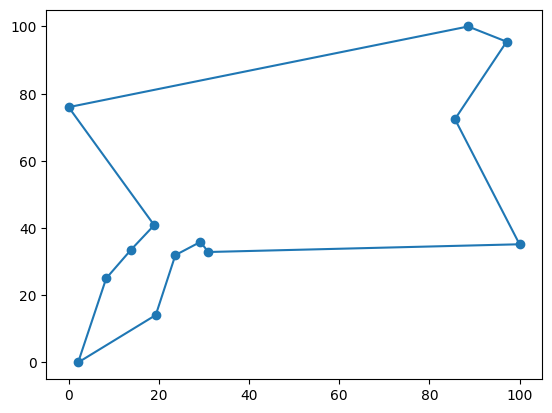

Route: [ 0  1  5  8  2 10  4 12  6  7 11  9  3]

Distance_scaled: 371.8602495129763


In [19]:
import matplotlib.pyplot as plt
new_cities_order = np.concatenate((np.array([scaled[route[i]] for i in range(len(route))]),np.array([scaled[0]])))
plt.scatter(scaled[:,0],scaled[:,1])
plt.plot(new_cities_order[:,0],new_cities_order[:,1])
plt.show()
print("Route: " + str(route) + "\n\nDistance_scaled: " + str(path_distance(route,scaled)))

In [24]:
Distance_km = path_distance(route, scaled) * 371.8602495129763
print(f"Jarak rute terpendek: {Distance_km} km")

Jarak rute terpendek: 138280.04516785298 km


In [25]:
order = pd.DataFrame(route, columns=["index"])
cities2["index"] = cities2.index
cities2
travel=order.merge(cities2, on ="index")

In [26]:
start= travel [0:1]
loop = travel._append(start)
loop

,index,name,description,latitude,longitude,lat_radians,lon_radians,x,y
0,0,Salatiga,Indonesia,-7.329997,110.506697,-0.127933,1.928706,-2213.629410,284.750520
1,1,Adelaide,Australia,-35.041720,138.814109,-0.611593,2.422763,-3925.559083,2752.968089
2,5,Budapest,Hungaria,47.491877,19.020375,0.828890,0.331968,4069.818004,4440.163087
3,8,Madrid,Spanyol,40.417452,-3.700841,0.705418,-0.064592,4840.387691,4122.035782
4,2,Baghdad,Irak,33.324774,44.367558,0.581627,0.774360,3805.543466,2502.130992
5,10,Nairobi,Kenya,-1.289474,36.820594,-0.022506,0.642641,5098.795950,-114.770682
6,4,Bangkok,Thailand,13.757731,100.512168,0.240118,1.754268,-1129.004945,-276.427213
7,12,Putra Jaya,Malaysia,2.926016,101.692319,0.051069,1.774866,-1289.438268,-65.907123
8,6,Ho Chi Minh City,Vietnam,10.794569,106.615193,0.188401,1.860786,-1789.503841,-341.190328
9,7,Las Vegas,USA,36.168906,-115.103667,0.631267,-2.008938,-2182.034325,-1595.189957


In [27]:
tsp = loop[["latitude", "longitude"]]
tsp.to_csv('tsp.csv', index=False)
from google.colab import files
files.download("tsp.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>